## Data Collection

Expanding the training corpus by sourcing and integrating four additional TalkBank corpora:

| Corpus | Participants | Task(s) | Diagnosis |
|--------|-------------|---------|----------|
| **Lu** | 54 | Cookie Theft picture description | Dementia, AD, MCI, vascular dementia |
| **Hopkins** | 36 | Cinderella narrative, picture description | Primary Progressive Aphasia (PPA) |
| **Kempler** | 6 | Conversation + Cookie Theft | Alzheimer's dementia |
| **DePaul** | 1 | Free speech, picture descriptions, Cinderella | Semantic PPA |

Each source is split into 80/20 train/test speaker-disjoint sets (DePaul is solely used for training since it has only one recording), then chunked into ≤30s participant (PAR) utterance segments.

In [1]:
import json
import os
from pathlib import Path
from collections import defaultdict
import soundfile as sf
import pandas as pd
import matplotlib.pyplot as plt

TRAIN_MANIFEST = Path("yasaman/train_manifest.jsonl")
TEST_MANIFEST  = Path("yasaman/test_manifest.jsonl")

def load_manifest(path):
    with open(path) as f:
        return [json.loads(l) for l in f if l.strip()]

train_records = load_manifest(TRAIN_MANIFEST)
test_records  = load_manifest(TEST_MANIFEST)
all_records   = train_records + test_records

print(f"Train clips : {len(train_records)}")
print(f"Test clips  : {len(test_records)}")
print(f"Total clips : {len(all_records)}")

Train clips : 658
Test clips  : 168
Total clips : 826


In [2]:
# ── Speaker counts ────────────────────────────────────────────────────────────
import re
_TASK_SUFFIX_RE = re.compile(r"(?<=\d)[A-Za-z]$")

def normalize_speaker(sid):
    """Strip trailing task letter, e.g. BBW8512a -> BBW8512"""
    return _TASK_SUFFIX_RE.sub("", sid) if sid else sid

train_speakers = {normalize_speaker(r.get("speaker_id", r.get("source_id", ""))) for r in train_records}
test_speakers  = {normalize_speaker(r.get("speaker_id", r.get("source_id", ""))) for r in test_records}

print(f"Train speakers : {len(train_speakers)}")
print(f"Test speakers  : {len(test_speakers)}")
print(f"Overlap        : {len(train_speakers & test_speakers)}  (should be 0)")

Train speakers : 149
Test speakers  : 43
Overlap        : 0  (should be 0)


In [3]:
# ── Audio duration ────────────────────────────────────────────────────────────
def total_hours(records):
    total_s = 0
    for r in records:
        try:
            info = sf.info(r["audio_path"])
            total_s += info.duration
        except Exception:
            pass
    return total_s / 3600

train_h = total_hours(train_records)
test_h  = total_hours(test_records)
print(f"Train audio : {train_h:.2f} h")
print(f"Test audio  : {test_h:.2f} h")
print(f"Total audio : {train_h + test_h:.2f} h")

Train audio : 4.40 h
Test audio  : 1.07 h
Total audio : 5.47 h


                  count
[uh]               1291
[unclear-speech]   1077
[um]                489
[short-pause]       459
[long-pause]        329
[medium-pause]      196
[laughter]          133
[non-verbal]        111


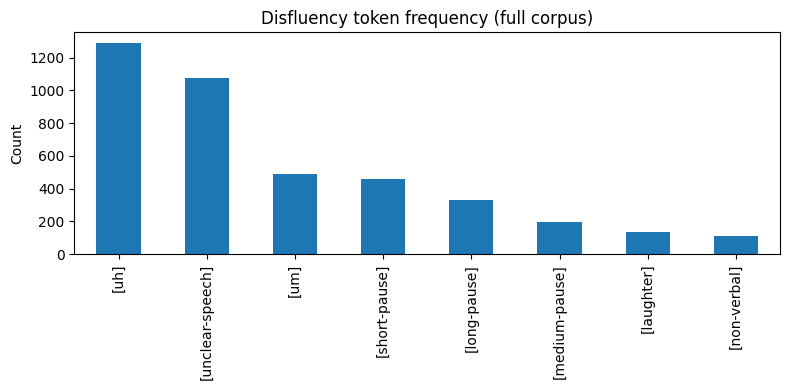

In [4]:
# ── Disfluency token frequency in references ──────────────────────────────────
DISFLUENCY_TOKENS = [
    "[short-pause]", "[medium-pause]", "[long-pause]",
    "[unclear-speech]", "[laughter]", "[non-verbal]", "[uh]", "[um]"
]

token_counts = defaultdict(int)
for r in all_records:
    text = r.get("text", "")
    for tok in DISFLUENCY_TOKENS:
        token_counts[tok] += text.count(tok)

df_tok = pd.DataFrame.from_dict(token_counts, orient="index", columns=["count"]).sort_values("count", ascending=False)
print(df_tok)

df_tok.plot(kind="bar", figsize=(8, 4), legend=False, title="Disfluency token frequency (full corpus)")
plt.ylabel("Count"); plt.tight_layout(); plt.show()

## Zero-Shot & Few-Shot Baselines

Establishing baselines for the unmodified **Qwen2-Audio-7B-Instruct** model before fine-tuning, to quantify how much the base model suppresses disfluencies.

**Zero-shot** (`zero_shot.py`): the model is given a system prompt describing the disfluency token legend and instructed to transcribe preserving all disfluencies. No examples are shown.

**Few-shot** (`few_shot.py`): the same system prompt is extended with four hand-crafted transcription examples demonstrating correct token usage across different disfluency patterns (filler + short pause, repetition + mixed pauses, long pause + unclear speech, full multi-sentence clip).

Both scripts run inference over the full test split (168 clips) and write predictions to JSONL. Evaluation uses `eval_preds.py`, which computes:
- **WER**
- **Disfluency token P/R/F1** per token and aggregated
- Hallucination rate (predicted tokens not in reference) and miss rate (reference tokens not predicted)

### Results


In [6]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 130

# ── Load results ──────────────────────────────────────────────────────────────
with open("yasaman/zero_shot_metrics_new2.json") as f:
    zero_shot_results = json.load(f)

with open("yasaman/few_shot_metrics_new2.json") as f:
    few_shot_results = json.load(f)

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"{'Metric':<35} {'Zero-shot':>12} {'Few-shot':>12}")
print("-" * 60)
zd = zero_shot_results["disfluency_metrics"]
fd = few_shot_results["disfluency_metrics"]
rows = [
    ("WER",                   zero_shot_results["wer"],                  few_shot_results["wer"]),
    ("Disfluency Precision",  zd["disfluency_token_precision"],           fd["disfluency_token_precision"]),
    ("Disfluency Recall",     zd["disfluency_token_recall"],              fd["disfluency_token_recall"]),
    ("Disfluency F1",         zd["disfluency_token_f1"],                  fd["disfluency_token_f1"]),
    ("Hallucination Rate",    zd["disfluency_token_hallucination_rate"],  fd["disfluency_token_hallucination_rate"]),
    ("Miss Rate",             zd["disfluency_token_miss_rate"],           fd["disfluency_token_miss_rate"]),
]
for label, z, f in rows:
    print(f"{label:<35} {z:>12.4f} {f:>12.4f}")

Metric                                 Zero-shot     Few-shot
------------------------------------------------------------
WER                                       0.5396       0.6634
Disfluency Precision                      0.3871       0.0436
Disfluency Recall                         0.0173       0.0216
Disfluency F1                             0.0331       0.0289
Hallucination Rate                        0.6129       0.9564
Miss Rate                                 0.9827       0.9784


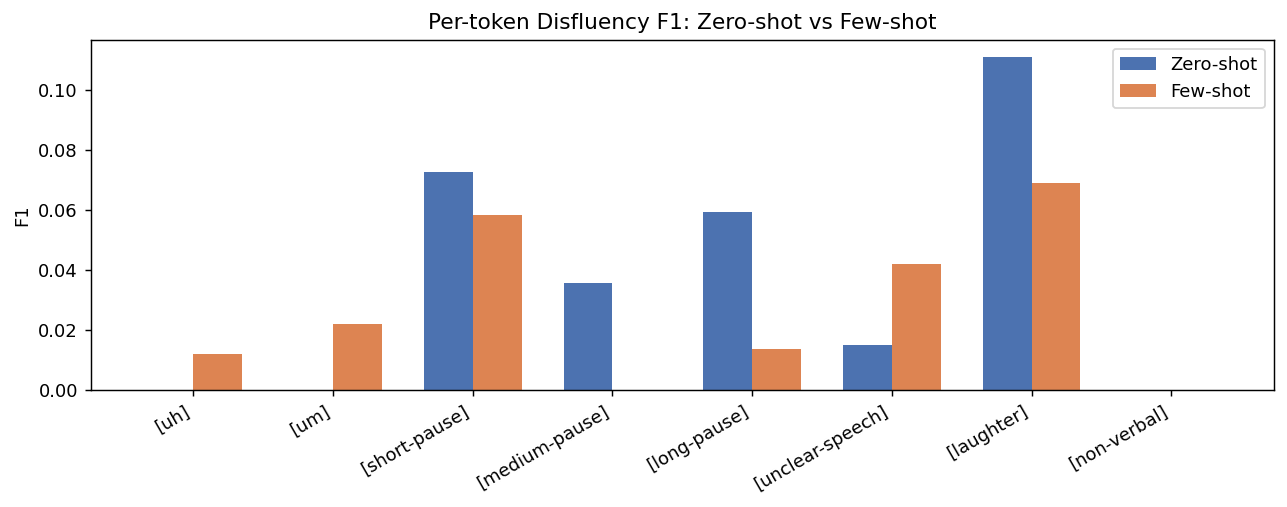

In [7]:
# ── Per-token F1 comparison ───────────────────────────────────────────────────
tokens = list(zero_shot_results["disfluency_metrics"]["per_token_stats"].keys())
z_f1 = [zero_shot_results["disfluency_metrics"]["per_token_stats"][t]["f1"] for t in tokens]
f_f1 = [few_shot_results["disfluency_metrics"]["per_token_stats"][t]["f1"] for t in tokens]

x = range(len(tokens))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([i - width/2 for i in x], z_f1, width, label="Zero-shot", color="#4C72B0")
ax.bar([i + width/2 for i in x], f_f1, width, label="Few-shot",  color="#DD8452")
ax.set_xticks(list(x))
ax.set_xticklabels(tokens, rotation=30, ha="right")
ax.set_ylabel("F1")
ax.set_title("Per-token Disfluency F1: Zero-shot vs Few-shot")
ax.legend()
plt.tight_layout()
plt.show()

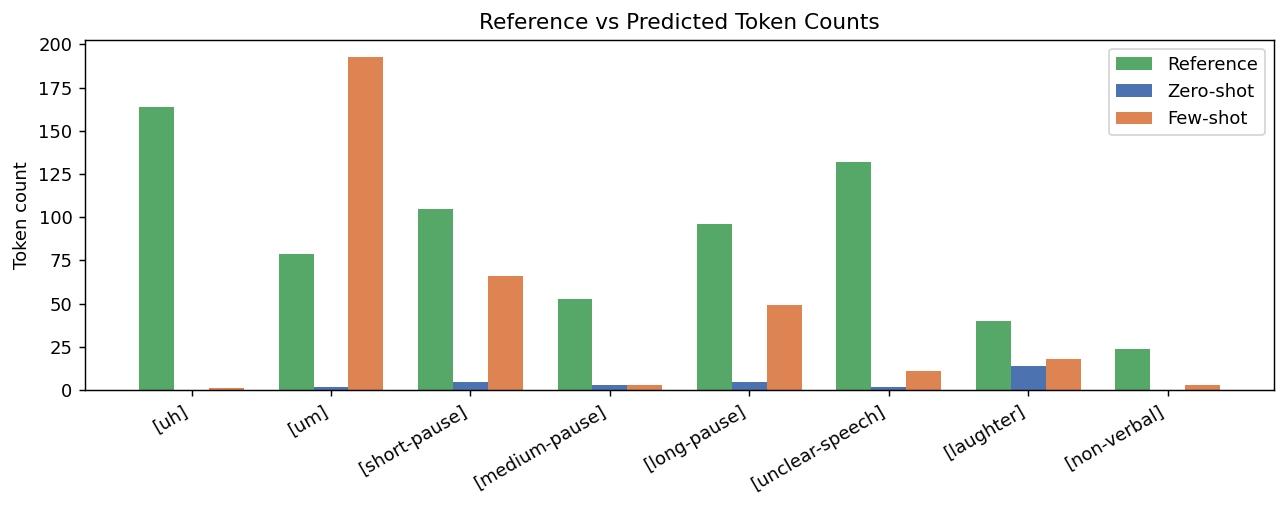

In [8]:
# ── Ref vs predicted token counts ────────────────────────────────────────────
ref_counts  = [zero_shot_results["disfluency_metrics"]["per_token_stats"][t]["ref_total"] for t in tokens]
z_pred      = [zero_shot_results["disfluency_metrics"]["per_token_stats"][t]["pred_total"] for t in tokens]
f_pred      = [few_shot_results["disfluency_metrics"]["per_token_stats"][t]["pred_total"] for t in tokens]

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.25
xi = list(range(len(tokens)))
ax.bar([i - w for i in xi],   ref_counts, w, label="Reference",  color="#55A868")
ax.bar([i     for i in xi],   z_pred,     w, label="Zero-shot",  color="#4C72B0")
ax.bar([i + w for i in xi],   f_pred,     w, label="Few-shot",   color="#DD8452")
ax.set_xticks(xi)
ax.set_xticklabels(tokens, rotation=30, ha="right")
ax.set_ylabel("Token count")
ax.set_title("Reference vs Predicted Token Counts")
ax.legend()
plt.tight_layout()
plt.show()

Both baselines confirm the core motivation of this project. The zero-shot model achieves a 53.96% WER and a disfluency token recall of 1.73% — it almost entirely suppresses the 693 disfluency tokens present in the 168 test references. The few-shot prompt drastically increases the number of predicted tokens (344 vs 31) but without accuracy. WER rises to 66.34%, meaning the model floods transcriptions with mostly incorrect tokens. The few-shot model is clearly pattern-matching the examples rather than grounding tokens in the audio signal. These results establish a strong quantitative case for fine-tuning.

## LoRA Fine-Tuning


In [9]:
with open("yasaman/loss_weight5.0_epochs5_lr2e-4_pre_post_train_eval_metrics.json") as f:
    results = json.load(f)

def get_metrics(results, split, stage):
    m  = results[stage][split]
    dm = m["disfluency_token_metrics"]
    return {
        "wer":       m["wer"],
        "f1":        dm["disfluency_token_f1"],
        "precision": dm["disfluency_token_precision"],
        "recall":    dm["disfluency_token_recall"],
        "halluc":    dm["disfluency_token_hallucination_rate"],
        "miss":      dm["disfluency_token_miss_rate"],
        "per_token": dm["per_token_stats"],
    }

before_test  = get_metrics(results, "test",  "before_train")
after_test   = get_metrics(results, "test",  "after_train")
before_train = get_metrics(results, "train", "before_train")
after_train  = get_metrics(results, "train", "after_train")

In [10]:
# ── Before vs After: summary table ───────────────────────────────────────────
print(f"{'Metric':<30} {'Before (train)':>16} {'After (train)':>16} {'Before (test)':>16} {'After (test)':>16}")
print("-" * 96)
rows = [
    ("WER",               before_train["wer"],       after_train["wer"],       before_test["wer"],       after_test["wer"]),
    ("Disfluency F1",     before_train["f1"],        after_train["f1"],        before_test["f1"],        after_test["f1"]),
    ("Precision",         before_train["precision"], after_train["precision"], before_test["precision"], after_test["precision"]),
    ("Recall",            before_train["recall"],    after_train["recall"],    before_test["recall"],    after_test["recall"]),
    ("Hallucination Rate",before_train["halluc"],    after_train["halluc"],    before_test["halluc"],    after_test["halluc"]),
    ("Miss Rate",         before_train["miss"],      after_train["miss"],      before_test["miss"],      after_test["miss"]),
]
for label, bt, at, bte, ate in rows:
    print(f"{label:<30} {bt:>16.4f} {at:>16.4f} {bte:>16.4f} {ate:>16.4f}")

Metric                           Before (train)    After (train)    Before (test)     After (test)
------------------------------------------------------------------------------------------------
WER                                      0.4865           0.1335           0.5368           0.3454
Disfluency F1                            0.0000           0.7972           0.0000           0.5031
Precision                                0.0000           0.8210           0.0000           0.5406
Recall                                   0.0000           0.7748           0.0000           0.4704
Hallucination Rate                       0.0000           0.1790           0.0000           0.4594
Miss Rate                                1.0000           0.2252           1.0000           0.5296


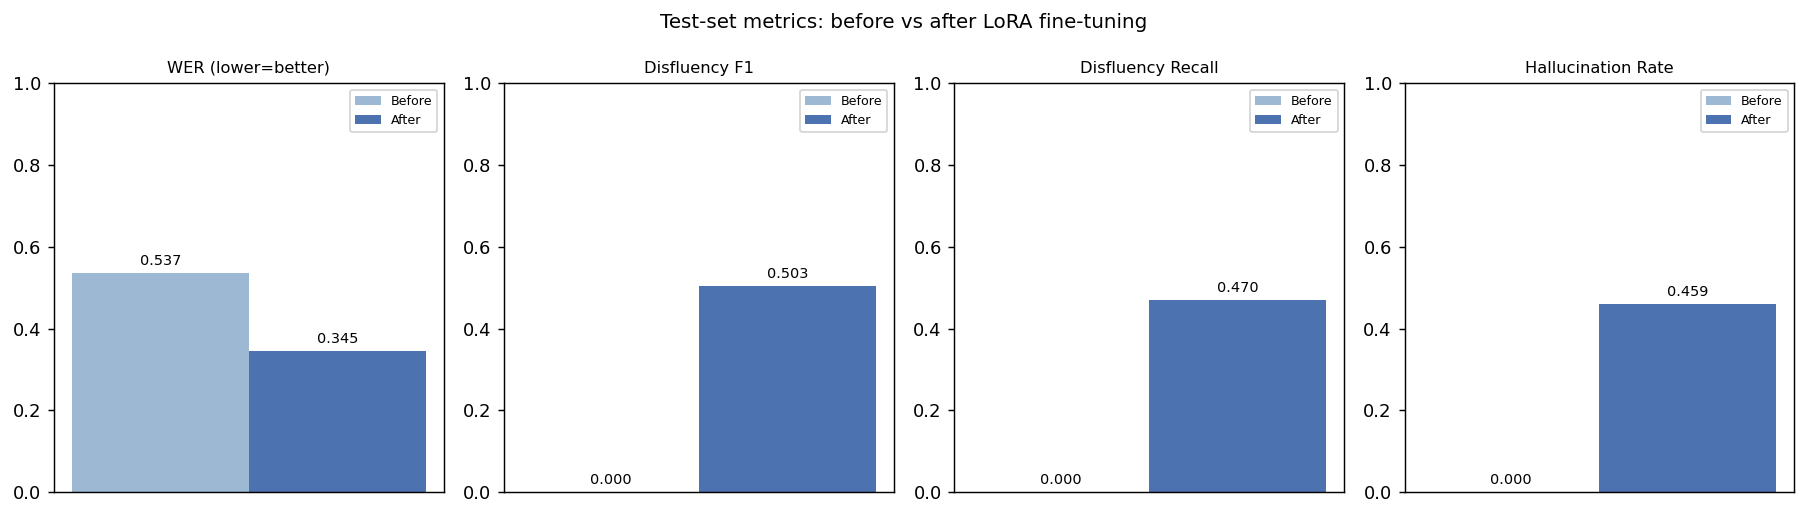

In [11]:
# ── Before vs After: bar chart (test set) ────────────────────────────────────
metrics = ["wer", "f1", "recall", "halluc"]
titles  = ["WER (lower=better)", "Disfluency F1", "Disfluency Recall", "Hallucination Rate"]
before_vals = [before_test[m] for m in metrics]
after_vals  = [after_test[m]  for m in metrics]

x = range(len(metrics))
w = 0.35
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, m, title, bv, av in zip(axes, metrics, titles, before_vals, after_vals):
    bars_b = ax.bar([0 - w/2], [bv], w, label="Before", color="#9DB8D2")
    bars_a = ax.bar([0 + w/2], [av], w, label="After",  color="#4C72B0")
    ax.set_xticks([]); ax.set_title(title, fontsize=9)
    ax.set_ylim(0, 1)
    ax.text(bars_b[0].get_x() + w/2, bv + 0.02, f"{bv:.3f}", ha="center", fontsize=8)
    ax.text(bars_a[0].get_x() + w/2, av + 0.02, f"{av:.3f}", ha="center", fontsize=8)
    ax.legend(fontsize=7)
fig.suptitle("Test-set metrics: before vs after LoRA fine-tuning", fontsize=11)
plt.tight_layout()
plt.show()

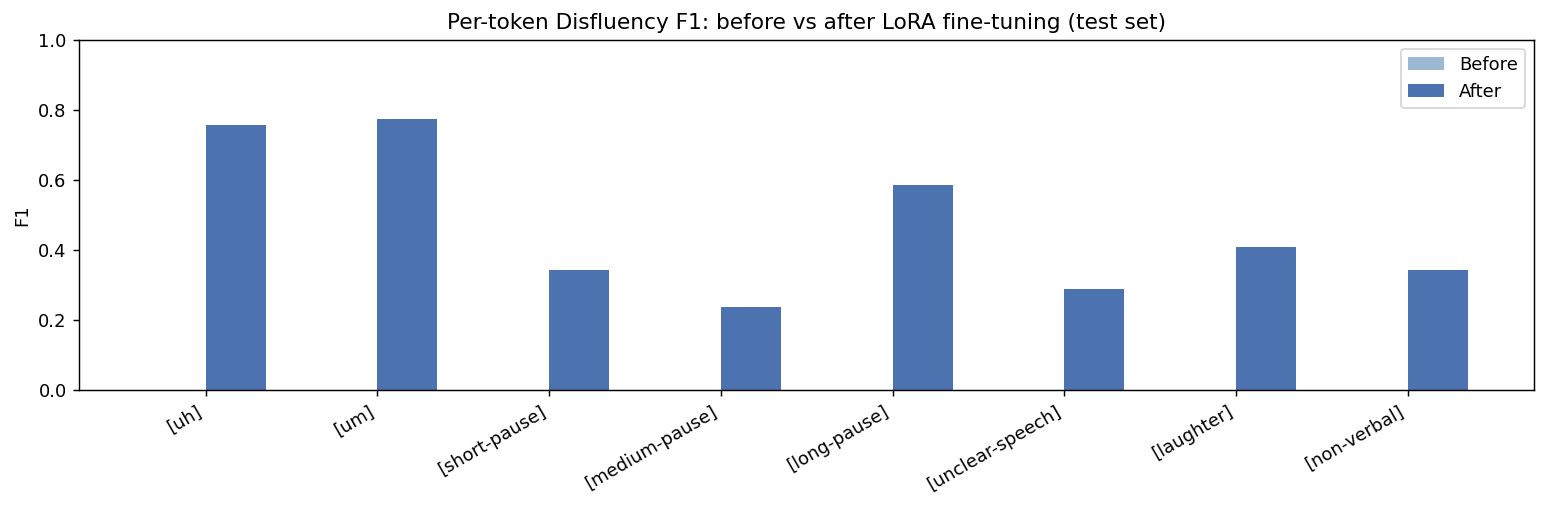

In [12]:
# ── Per-token F1: before vs after (test set) ─────────────────────────────────
tokens = list(after_test["per_token"].keys())
f1_before = [before_test["per_token"][t]["f1"] for t in tokens]
f1_after  = [after_test["per_token"][t]["f1"]  for t in tokens]

x = range(len(tokens))
w = 0.35
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar([i - w/2 for i in x], f1_before, w, label="Before", color="#9DB8D2")
ax.bar([i + w/2 for i in x], f1_after,  w, label="After",  color="#4C72B0")
ax.set_xticks(list(x))
ax.set_xticklabels(tokens, rotation=30, ha="right")
ax.set_ylabel("F1"); ax.set_ylim(0, 1)
ax.set_title("Per-token Disfluency F1: before vs after LoRA fine-tuning (test set)")
ax.legend()
plt.tight_layout()
plt.show()

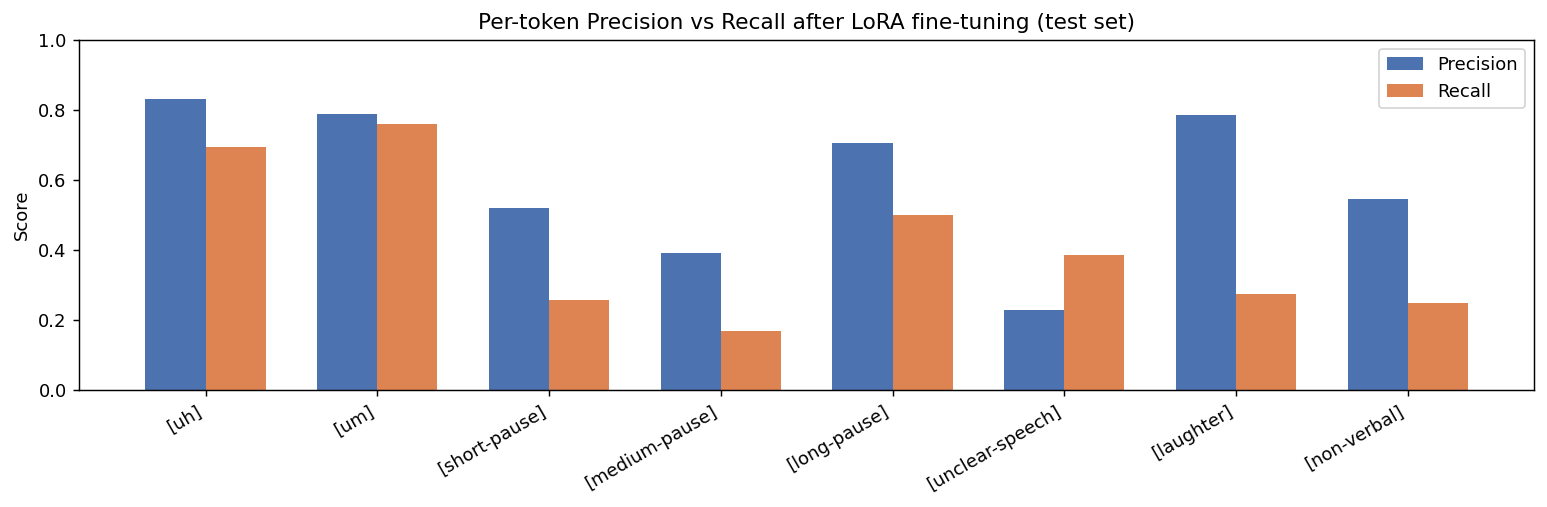

In [13]:
# ── Per-token recall and precision after training (test set) ──────────────────
recall_after    = [after_test["per_token"][t]["recall"]    for t in tokens]
precision_after = [after_test["per_token"][t]["precision"] for t in tokens]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar([i - w/2 for i in x], precision_after, w, label="Precision", color="#4C72B0")
ax.bar([i + w/2 for i in x], recall_after,    w, label="Recall",    color="#DD8452")
ax.set_xticks(list(x))
ax.set_xticklabels(tokens, rotation=30, ha="right")
ax.set_ylabel("Score"); ax.set_ylim(0, 1)
ax.set_title("Per-token Precision vs Recall after LoRA fine-tuning (test set)")
ax.legend()
plt.tight_layout()
plt.show()

### Observations
- **WER** drops from 53.68% → 34.54% on test after fine-tuning.
- **Disfluency F1** jumps from 0 → 0.503 on test: the model learns to emit tokens it completely suppressed before training.
- `[medium-pause]` remains the weakest token (F1=0.237), likely due to low frequency and boundary ambiguity with short and long pauses.
- Hallucination rate on test is 45.94%: the model over-predicts `[unclear-speech]` in particular, suggesting the threshold for that token is too loose.

## Differential Learning Rates

Experimenting with **differential (per-component) learning rates** to give each trainable part of the model an appropriate update step size
| Component | Learning Rate |
|-----------|--------------|
| Audio encoder (LoRA) | 5e-5 |
| LM backbone (LoRA) | 1e-4 |
| Multimodal projector | 1e-4 |
| New disfluency token embeddings | 1e-3 |

In [14]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 130

DIFF_LR_RESULTS_PATH = 'yasaman/diff_lr_pre_post_train_eval_metrics.json'

with open(DIFF_LR_RESULTS_PATH) as f:
    diff_lr_results = json.load(f)

def get_metrics(results, split, stage):
    m  = results[stage][split]
    dm = m['disfluency_token_metrics']
    return {
        'wer':       m['wer'],
        'f1':        dm['disfluency_token_f1'],
        'oa_f1':     dm['disfluency_token_order_f1'],
        'precision': dm['disfluency_token_precision'],
        'recall':    dm['disfluency_token_recall'],
        'halluc':    dm['disfluency_token_hallucination_rate'],
        'miss':      dm['disfluency_token_miss_rate'],
        'per_token': dm['per_token_stats'],
    }

before_train = get_metrics(diff_lr_results, 'train', 'before_train')
after_train  = get_metrics(diff_lr_results, 'train', 'after_train')
before_test  = get_metrics(diff_lr_results, 'test',  'before_train')
after_test   = get_metrics(diff_lr_results, 'test',  'after_train')

In [15]:
# ── Summary table: before vs after (diff-LR run) ─────────────────────────
print(f"{'Metric':<30} {'Before (train)':>16} {'After (train)':>16} {'Before (test)':>16} {'After (test)':>16}")
print('-' * 96)
rows = [
    ('WER',                before_train['wer'],       after_train['wer'],       before_test['wer'],       after_test['wer']),
    ('Disfluency F1',      before_train['f1'],        after_train['f1'],        before_test['f1'],        after_test['f1']),
    ('Order-aware F1',     before_train['oa_f1'],     after_train['oa_f1'],     before_test['oa_f1'],     after_test['oa_f1']),
    ('Precision',          before_train['precision'], after_train['precision'], before_test['precision'], after_test['precision']),
    ('Recall',             before_train['recall'],    after_train['recall'],    before_test['recall'],    after_test['recall']),
    ('Hallucination Rate', before_train['halluc'],    after_train['halluc'],    before_test['halluc'],    after_test['halluc']),
    ('Miss Rate',          before_train['miss'],      after_train['miss'],      before_test['miss'],      after_test['miss']),
]
for label, bt, at, bte, ate in rows:
    print(f'{label:<30} {bt:>16.4f} {at:>16.4f} {bte:>16.4f} {ate:>16.4f}')

Metric                           Before (train)    After (train)    Before (test)     After (test)
------------------------------------------------------------------------------------------------
WER                                      0.4865           0.0008           0.5368           0.3407
Disfluency F1                            0.0000           0.9976           0.0000           0.5198
Order-aware F1                           0.0000           0.9975           0.0000           0.4179
Precision                                0.0000           0.9997           0.0000           0.5764
Recall                                   0.0000           0.9956           0.0000           0.4733
Hallucination Rate                       0.0000           0.0003           0.0000           0.4236
Miss Rate                                1.0000           0.0044           1.0000           0.5267


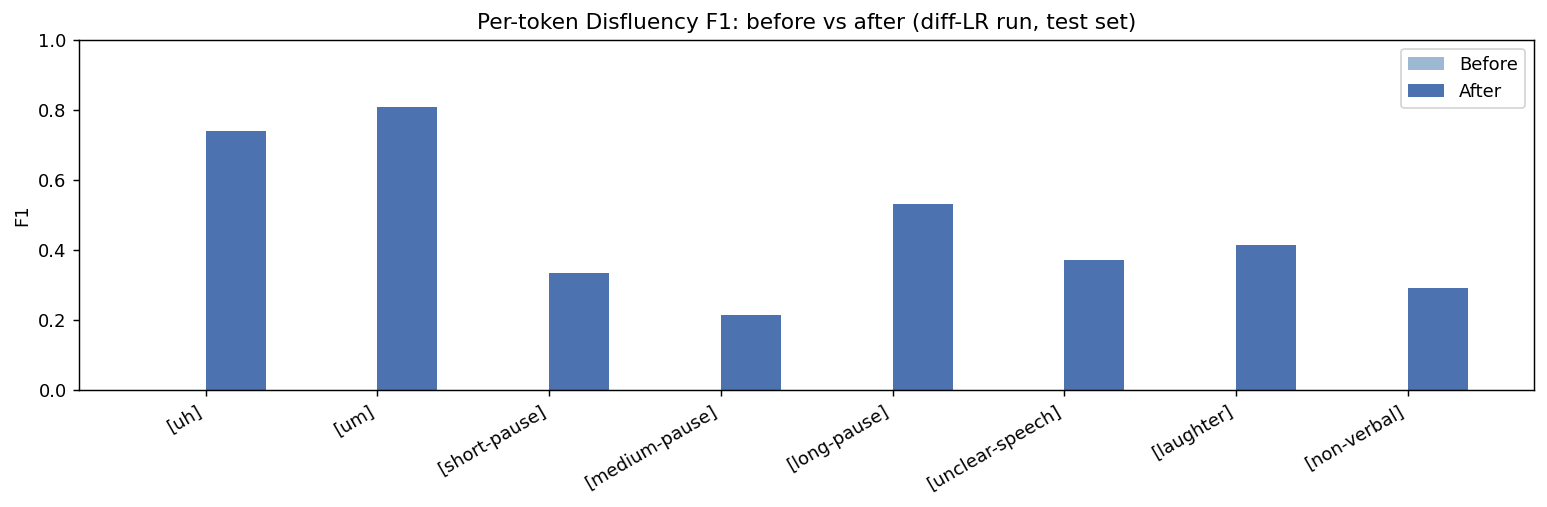

In [16]:
# ── Per-token F1 after diff-LR training (test set) ───────────────────────
tokens = list(after_test['per_token'].keys())
f1_before = [before_test['per_token'][t]['f1'] for t in tokens]
f1_after  = [after_test['per_token'][t]['f1']  for t in tokens]

x = range(len(tokens))
w = 0.35
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar([i - w/2 for i in x], f1_before, w, label='Before', color='#9DB8D2')
ax.bar([i + w/2 for i in x], f1_after,  w, label='After',  color='#4C72B0')
ax.set_xticks(list(x))
ax.set_xticklabels(tokens, rotation=30, ha='right')
ax.set_ylabel('F1'); ax.set_ylim(0, 1)
ax.set_title('Per-token Disfluency F1: before vs after (diff-LR run, test set)')
ax.legend()
plt.tight_layout()
plt.show()

### Observations
- The differential learning rate setup achieves test WER **0.341** and disfluency F1 **0.520**
- Filler tokens `[uh]` and `[um]` benefit most, with F1 scores around 0.74 and 0.81 respectively, consistent with their higher frequency and acoustic salience.
- Using a higher learning rate (1e-3) for the new disfluency token embeddings accelerates their convergence without destabilizing the pre-trained encoder weights.
- The gap between train and test performance remains, indicating that generalization to unseen speakers is a bottleneck.

## QA Dataset Generation

To evaluate whether improved transcription translates into better diagnostic reasoning, I constructed an audio QA benchmark from the test-set reference transcripts. QA pairs were generated using **Claude 3.5 Sonnet** via the Claude.ai chat interface, with a structured prompt that asked the model to produce questions across two categories:

- **Content questions** (multiple-choice and yes/no): test literal comprehension of what the speaker said
- **Disfluency questions** (count-based and yes/no): test awareness of speech irregularities (e.g. *"How many time does the speaker say 'uh' or 'um'?"*, *"Does the participant take any pauses during this recording?"*)

To prevent answer-position bias in yes/no and multiple-choice questions, answer options are shuffled and to ensure roughly balanced distributions. The final dataset contains **672 questions** across 168 test clips (4 questions per clip): 336 yes/no, 168 multiple-choice, and 168 count questions.

In [17]:
# ── QA dataset statistics ────────────────────────────────────────────────
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 130

QA_DATASET_PATH = 'yasaman/qa_test_full.jsonl'

with open(QA_DATASET_PATH) as f:
    qa_rows = [json.loads(l) for l in f if l.strip()]

df_qa = pd.DataFrame(qa_rows)
print(f'Total questions : {len(df_qa)}')
print(f'Unique clips    : {df_qa["audio_path"].nunique()}')
print()
print('By answer_type:')
print(df_qa['answer_type'].value_counts().to_string())
print()
print('By category:')
print(df_qa['category'].value_counts().to_string())

Total questions : 672
Unique clips    : 168

By answer_type:
answer_type
yes_no             336
multiple_choice    168
count              168

By category:
category
content       336
disfluency    336


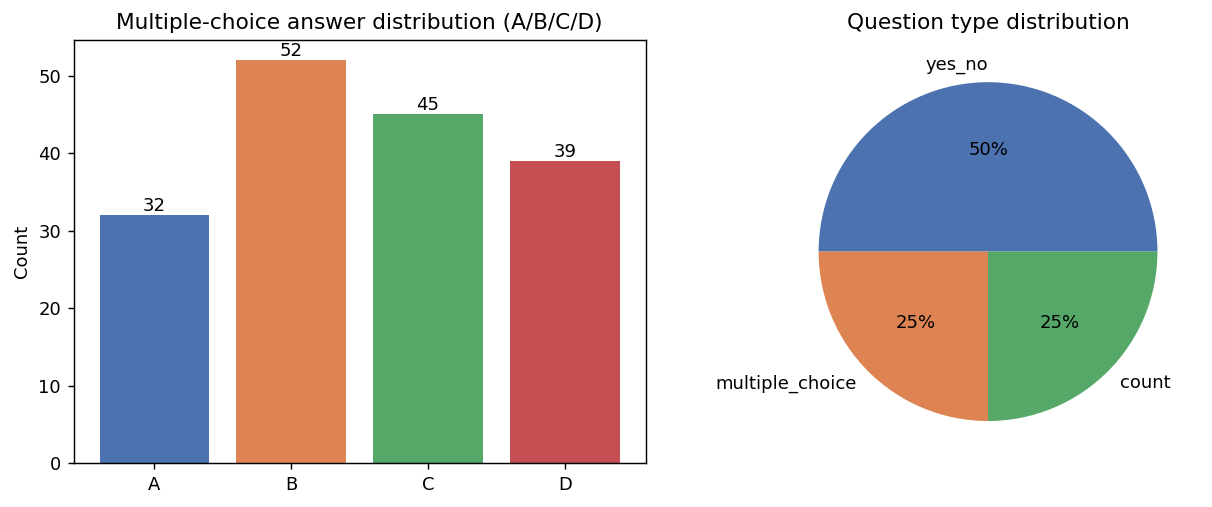

In [18]:
# ── Answer distribution checks ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# MCQ answer distribution (A/B/C/D balance)
mc_df = df_qa[df_qa['answer_type'] == 'multiple_choice']
mc_counts = mc_df['answer'].str.strip().str.upper().value_counts().sort_index()

axes[0].bar(mc_counts.index, mc_counts.values, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
axes[0].set_title('Multiple-choice answer distribution (A/B/C/D)')
axes[0].set_ylabel('Count')
for i, (label, v) in enumerate(mc_counts.items()):
    axes[0].text(i, v + 0.5, str(v), ha='center')

# Question type breakdown
type_counts = df_qa['answer_type'].value_counts()
axes[1].pie(type_counts.values, labels=type_counts.index, autopct='%1.0f%%',
            colors=['#4C72B0', '#DD8452', '#55A868'])
axes[1].set_title('Question type distribution')

plt.tight_layout()
plt.show()

## QA Evaluation

The base model is evaluated on the QA benchmark under **three inference conditions**:

1. **Audio-only**: the model receives only the audio clip and the question — no transcript
2. **Audio + gold transcript**: the model receives the audio plus the reference transcript as context
3. **Audio + fine-tuned transcript**: the model receives the audio plus a transcript generated by our best fine-tuned model

The evaluation script uses question-type-aware metrics: exact-match accuracy for yes/no and multiple-choice, and a partial-credit distance-based score for count questions (along with off-by-one accuracy and MAE). Results are broken down by question type and category (content vs disfluency).

In [23]:
# ── Load the QA result files ───────────────────────────────────────
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 130

RESULTS = {
    'Audio-only':              'yasaman/metrics_base_single.json',
    'Audio + Gold transcript':  'yasaman/metrics_base_gold_transcripts.json',
    'Audio + Fine-tuned transcript': 'yasaman/metrics_base_with_finetuned_transcripts.json',
}

# Hardcoded from result JSONs (if files are unavailable)
HARDCODED = {
    'Audio-only': {
        'overall': 0.5714, 'yes_no': 0.6845, 'multiple_choice': 0.6964,
        'count': 0.2202, 'content': 0.7887, 'disfluency': 0.3542,
        'count_obo': 0.7143, 'count_mae': 1.35,
    },
    'Audio + Gold transcript': {
        'overall': 0.5729, 'yes_no': 0.7381, 'multiple_choice': 0.7202,
        'count': 0.0952, 'content': 0.7708, 'disfluency': 0.3750,
        'count_obo': 0.3929, 'count_mae': 2.13,
    },
    'Audio + Fine-tuned transcript': {
        'overall': 0.5372, 'yes_no': 0.6786, 'multiple_choice': 0.7024,
        'count': 0.0893, 'content': 0.7411, 'disfluency': 0.3333,
        'count_obo': 0.3869, 'count_mae': 2.10,
    },
}

def load_summary(path, fallback_key):
    try:
        with open(path) as f:
            d = json.load(f)
        return {
            'overall':         d['overall_accuracy'],
            'yes_no':          d['by_type']['yes_no']['accuracy'],
            'multiple_choice': d['by_type']['multiple_choice']['accuracy'],
            'count':           d['by_type']['count']['accuracy'],
            'content':         d['by_category']['content']['accuracy'],
            'disfluency':      d['by_category']['disfluency']['accuracy'],
            'count_obo':       d['by_type']['count']['off_by_one_accuracy'],
            'count_mae':       d['by_type']['count']['mae'],
        }
    except FileNotFoundError:
        print(f'  [{fallback_key}] result file not found — using hardcoded values')
        return HARDCODED[fallback_key]

summaries = {k: load_summary(v, k) for k, v in RESULTS.items()}
print('Results loaded for:', list(summaries.keys()))

Results loaded for: ['Audio-only', 'Audio + Gold transcript', 'Audio + Fine-tuned transcript']


In [24]:
# ── Summary table ─────────────────────────────────────────────────────────
conditions = list(summaries.keys())
metrics_labels = ['overall', 'yes_no', 'multiple_choice', 'count', 'content', 'disfluency']
display_labels = ['Overall', 'Yes/No', 'Multiple Choice', 'Count', 'Content', 'Disfluency']

header = f"{'Metric':<20}" + ''.join(f"{c:>30}" for c in conditions)
print(header)
print('-' * (20 + 30 * len(conditions)))
for m, label in zip(metrics_labels, display_labels):
    row = f'{label:<20}' + ''.join(f"{summaries[c][m]:>30.4f}" for c in conditions)
    print(row)

print()
print('Count-specific metrics:')
for metric, label in [('count_obo', 'Off-by-one accuracy'), ('count_mae', 'MAE')]:
    row = f'{label:<20}' + ''.join(f"{summaries[c][metric]:>30.4f}" for c in conditions)
    print(row)

Metric                                  Audio-only       Audio + Gold transcript Audio + Fine-tuned transcript
--------------------------------------------------------------------------------------------------------------
Overall                                     0.5714                        0.5729                        0.5372
Yes/No                                      0.6845                        0.7381                        0.6786
Multiple Choice                             0.6964                        0.7202                        0.7024
Count                                       0.2202                        0.0952                        0.0893
Content                                     0.7887                        0.7708                        0.7411
Disfluency                                  0.3542                        0.3750                        0.3333

Count-specific metrics:
Off-by-one accuracy                         0.7143                        0.3929       

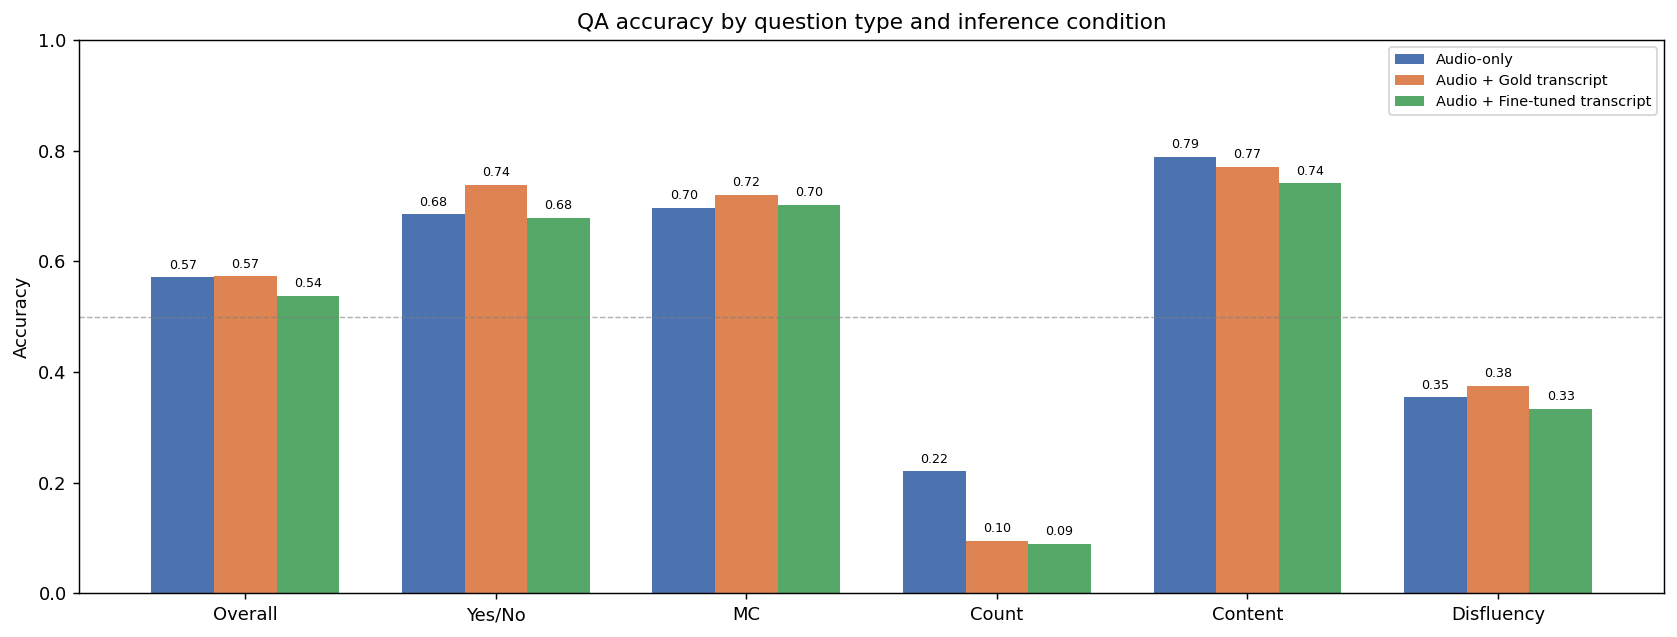

In [25]:
# ── Grouped bar chart: accuracy by question type ──────────────────────────
import numpy as np

type_metrics = ['overall', 'yes_no', 'multiple_choice', 'count', 'content', 'disfluency']
type_labels  = ['Overall', 'Yes/No', 'MC', 'Count', 'Content', 'Disfluency']
colors = ['#4C72B0', '#DD8452', '#55A868']

x = np.arange(len(type_labels))
w = 0.25

fig, ax = plt.subplots(figsize=(13, 5))
for i, (cond, color) in enumerate(zip(conditions, colors)):
    vals = [summaries[cond][m] for m in type_metrics]
    bars = ax.bar(x + (i - 1) * w, vals, w, label=cond, color=color)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{v:.2f}', ha='center', va='bottom', fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(type_labels)
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1.0)
ax.set_title('QA accuracy by question type and inference condition')
ax.legend(loc='upper right', fontsize=8)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
plt.tight_layout()
plt.show()

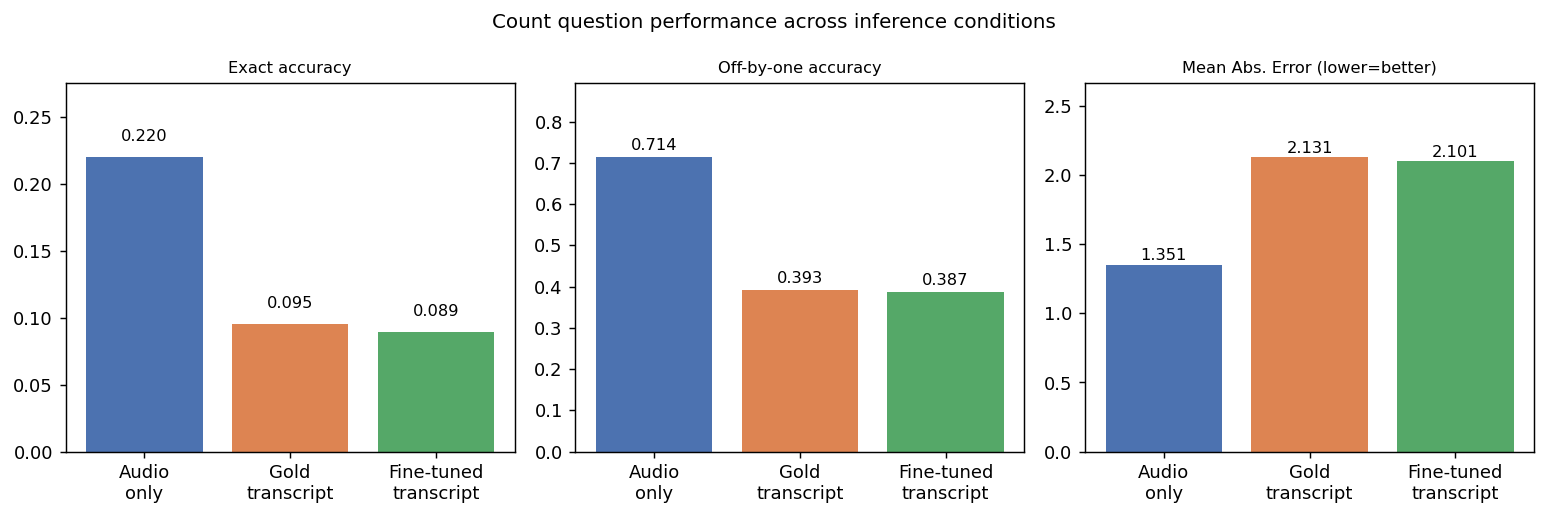

In [26]:
# ── Count questions deep-dive ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

count_metrics = ['count', 'count_obo', 'count_mae']
count_labels  = ['Exact accuracy', 'Off-by-one accuracy', 'Mean Abs. Error (lower=better)']

for ax, metric, label in zip(axes, count_metrics, count_labels):
    vals = [summaries[c][metric] for c in conditions]
    short_labels = ['Audio\nonly', 'Gold\ntranscript', 'Fine-tuned\ntranscript']
    bars = ax.bar(short_labels, vals, color=colors)
    ax.set_title(label, fontsize=9)
    ax.set_ylim(0, max(vals) * 1.25)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{v:.3f}', ha='center', va='bottom', fontsize=9)

fig.suptitle('Count question performance across inference conditions', fontsize=11)
plt.tight_layout()
plt.show()

### Observations
- **Content questions** (yes/no + MC) are answered reasonably well across all conditions, reaching 70–79% accuracy. This suggests the base model has sufficient audio comprehension for literal content.
- **Count questions** are the hardest category (22% audio-only). Strikingly, adding the gold transcript dramatically worsens count accuracy (22% → 9.5%), likely because the model conflates disfluency tokens in the transcript text with ordinary words.
- **Fine-tuned transcripts** perform worse still on overall accuracy (53.7%), consistent with error propagation: transcription imperfections introduce noise that misleads the QA model.
- These results motivate a jointly optimized transcription–QA objective over disfluency-rich transcripts as future work.